In [1]:
%load_ext autoreload
%autoreload 2

In [15]:
from frag_gnn.runner import load_config, init_dataset, init_dataloader
from frag_gnn.pl_model import FragGNNPL
from frag_gnn.dataset import SpecMolFragDataset
from frag_gnn.utils.misc_utils import scatter_reduce, scatter_argmax, scatter_argtopk, EPS, booltype, scatter_masked_softmax, scatter_logsumexp, safelog, LOG_ZERO, flatten_lol, js_div
from frag_gnn.utils.script_utils import init_wandb_ckpt, run_inference, select_model_vals, sparse_kl, log_mean, log_std, pearson_r
from frag_gnn.loss import sparse_conditional_entropy_fn, sparse_cosine_distance_hungarian
from frag_gnn.utils.frag_utils import load_frag_d
from frag_gnn.graff.dataset import calculate_prec_formula
from frag_gnn.graff.data_utils import fit_ann_library
from frag_gnn.utils.data_utils import composition_to_string
from frag_gnn.utils.spec_utils import calculate_match_mzs

import numpy as np
import torch as th
import pandas as pd
import argparse	
import wandb
import os
from pprint import pprint
from tqdm import tqdm
from pyteomics.mass import Composition

In [3]:
# load ann_df
# get formulae from products
proc_dp = "../data/proc/nist20mona23v3"
spec_df = pd.read_pickle(f"{proc_dp}/spec_df.pkl")
mol_df = pd.read_pickle(f"{proc_dp}/mol_df.pkl")
ann_df = pd.read_pickle(f"{proc_dp}/ann_df.pkl")

In [4]:
print(ann_df.columns)

Index(['dset_spec_id', 'mol_id', 'dset', 'spec_id', 'prec_type', 'formula',
       'ann_peak_mzs', 'ann_products', 'ann_losses', 'ann_isotopes',
       'ann_exact_mzs'],
      dtype='object')


In [5]:
# merge ann_df
m_ann_df = ann_df[["spec_id","ann_products","ann_exact_mzs"]].copy()
m_ann_df = m_ann_df.merge(spec_df[["spec_id","group_id"]], on="spec_id", how="inner")
m_ann_df = m_ann_df.drop(columns="spec_id").groupby("group_id").agg({"ann_products":list, "ann_exact_mzs":list}).reset_index()

In [6]:
# dedup formulae
def formula_dedup_fn(row):
    formulae = flatten_lol(row["ann_products"])
    mzs = flatten_lol(row["ann_exact_mzs"])
    assert len(formulae) == len(mzs), (len(formulae), len(mzs))
    formulae_dedup = []
    mzs_dedup = []
    for i in range(len(formulae)):
        formula = formulae[i]
        mz = mzs[i]
        if formula not in formulae_dedup:
            assert mz not in mzs_dedup, (i, mz, mzs_dedup)
            formulae_dedup.append(formula)
            mzs_dedup.append(mz)
    # assert len(formulae_dedup) == len(set(formulae_dedup)), (len(formulae_dedup), len(set(formulae_dedup)))
    out_d = {
        "group_id": row["group_id"],
        "formulae_dedup": formulae_dedup,
        "mzs_dedup": mzs_dedup
    }
    return out_d

m_ann_df = m_ann_df.apply(formula_dedup_fn, axis=1, result_type="expand")

In [7]:
print(ann_df["spec_id"].nunique())
print(m_ann_df["group_id"].nunique())
print(m_ann_df.columns)

397057
60885
Index(['group_id', 'formulae_dedup', 'mzs_dedup'], dtype='object')


In [8]:
formula_vals_fp = "../inference_outputs/d4_v3_formula/scaffold/fraggnn_d4/s0/test.pkl"
formula_vals = th.load(formula_vals_fp)

In [9]:
# get molecule ids
group_ids = formula_vals["unique_id"].flatten().numpy()
id_df = spec_df[["spec_id","mol_id","group_id"]]
id_df = id_df[id_df["group_id"].isin(group_ids)]
group_mol_df = id_df[["group_id","mol_id"]].drop_duplicates()
mol_ids = group_mol_df.set_index("group_id").loc[group_ids,"mol_id"].values

In [10]:
print(len(mol_ids))

3341


In [11]:
# use molecule id to load frag_d
mol_ids_str = [str(mol_id) for mol_id in mol_ids]
frag_d_d = {}
frag_dp = "../data/frag/nist20mona23v3_d4_h4_isoFalse_nb3/dags"
for mol_id_str in tqdm(mol_ids_str):
    frag_d_d[int(mol_id_str)] = load_frag_d(mol_id_str, frag_dp, is_compressed=True)

  0%|          | 0/3341 [00:00<?, ?it/s]

100%|██████████| 3341/3341 [01:59<00:00, 27.91it/s]


In [12]:
np.isin(group_ids,m_ann_df["group_id"]).mean()

0.9865309787488776

In [19]:
x_idxs = th.tensor([1,2,3])
x_logprobs = th.log(th.tensor([0.5,0.2,0.3]))
# y_idxs = th.tensor([3,6,7])
# y_logprobs = th.log(th.tensor([0.2,0.4,0.4]))
y_idxs = th.tensor([1,2,3])
y_logprobs = th.log(th.tensor([0.5,0.2,0.3]))
js_div(x_idxs, x_logprobs, y_idxs, y_logprobs)

tensor(0.)

In [31]:
unique_ids = formula_vals["unique_id"]
true_batch_idxs = formula_vals["true_batch_idxs"]
pred_batch_idxs = formula_vals["pred_batch_idxs"]
true_mzs = formula_vals["true_mzs"]
true_logprobs = formula_vals["true_logprobs"]
pred_mzs = formula_vals["pred_mzs"]
pred_logprobs = formula_vals["pred_logprobs"]
spec_batch_idxs = th.arange(unique_ids.shape[0])
pred_formula_logprobs = formula_vals["pred_formula_logprobs"]
pred_formula_batch_idxs = formula_vals["pred_formula_batch_idxs"]
pred_formula_formula_idxs = formula_vals["pred_formula_formula_idxs"]
formula_idx_cumsum = th.cumsum(th.cat(
    [
        th.zeros([1],dtype=th.long),
        th.unique(pred_formula_batch_idxs, return_counts=True)[1]
    ], dim=0), dim=0
)

m_ann_df_cp = m_ann_df.copy().set_index("group_id")

thresholds = [0., 1e-6, 1e-5, 0.001, 0.01]

# ann_formulae, pred_formulae = [], []
jsds = []
coverages, peak_coverages, w_peak_coverages = [], [], []

# iterate over the group truth data
# for i in tqdm(range(len(group_ids))):
for i in tqdm(range(300)):
# for i in tqdm(range(1)):
    i_group_id = group_ids[i]
    i_mol_id = mol_ids[i]
    if i_group_id not in m_ann_df_cp.index:
        continue
    i_frag_d = frag_d_d[i_mol_id]
    i_formula_idx_to_str = i_frag_d["idx_to_formula"]
    # pprint(i_formula_idx_to_str)
    i_mask = (unique_ids == i_group_id).flatten()
    i_batch_idx = spec_batch_idxs[i_mask].item()
    i_pred_peak_mask = (pred_batch_idxs == i_batch_idx)
    i_pred_mzs = pred_mzs[i_pred_peak_mask]
    # i_pred_logprobs = pred_logprobs[i_pred_peak_mask]
    i_true_peak_mask = (true_batch_idxs == i_batch_idx)
    i_true_mzs = true_mzs[i_true_peak_mask]
    i_true_logprobs = true_logprobs[i_true_peak_mask]
    assert th.isclose(th.logsumexp(i_true_logprobs,dim=0),th.tensor(0.),rtol=0.,atol=1e-4), th.logsumexp(i_true_logprobs,dim=0)
    
    i_formula_mask = (pred_formula_batch_idxs == i_batch_idx).flatten()
    i_pred_formula_logprobs = pred_formula_logprobs[i_formula_mask][1:]
    assert th.isclose(th.logsumexp(i_pred_formula_logprobs,dim=0),th.tensor(0.),rtol=0.,atol=1e-4), th.logsumexp(i_pred_formula_logprobs,dim=0)
    i_pred_formula_idxs = pred_formula_formula_idxs[i_formula_mask] - formula_idx_cumsum[i_batch_idx]
    assert i_pred_formula_idxs[0] == 0, i_pred_formula_idxs
    i_pred_formula_idxs = i_pred_formula_idxs[1:]
    # TODO: modify to account for prec_type properly
    i_pred_formulae = [
        composition_to_string(Composition(formula=i_formula_idx_to_str[idx.item()]) + Composition(formula="H")) 
        for idx in i_pred_formula_idxs
    ]
    i_pred_formulae = np.array(i_pred_formulae)
    i_ann_formulae = m_ann_df_cp.loc[i_group_id,"formulae_dedup"]
    i_ann_formulae = [
        composition_to_string(Composition(formula=formula)) for formula in i_ann_formulae
    ]
    i_ann_formulae = np.array(i_ann_formulae)
    i_ann_mzs = th.tensor(m_ann_df_cp.loc[i_group_id,"mzs_dedup"])

    # get idxs
    i_both_formulae = np.union1d(i_pred_formulae, i_ann_formulae)
    i_both_formula_idxs = np.arange(len(i_both_formulae))
    i_pred_formula_idxs = th.as_tensor(i_both_formula_idxs[np.isin(i_both_formulae, i_pred_formulae)])
    i_ann_formula_idxs = th.as_tensor(i_both_formula_idxs[np.isin(i_both_formulae, i_ann_formulae)])
    assert i_pred_formula_idxs.shape[0] == len(i_pred_formulae), (i_pred_formula_idxs.shape[0], len(i_pred_formulae))
    assert i_ann_formula_idxs.shape[0] == len(i_ann_formulae), (i_ann_formula_idxs.shape[0], len(i_ann_formulae))
    assert i_pred_formula_idxs.shape[0] == i_pred_formula_logprobs.shape[0], (i_pred_formula_idxs.shape[0], i_pred_formula_logprobs.shape[0])

    # calculate i_true_formula_logprobs
    # match formulae within 10 ppm
    i_ann_mz_match_mask = calculate_match_mzs(
        i_ann_mzs, 
        i_true_mzs,
        tolerance=1e-5, # 10 ppm
        relative=True
    ) # A x T

    i_ann_formula_logprobs = (i_true_logprobs.unsqueeze(0) - th.log(th.sum(i_ann_mz_match_mask, dim=1, keepdim=True)))
    i_ann_formula_logprobs[~i_ann_mz_match_mask] = LOG_ZERO(i_ann_formula_logprobs.dtype)
    i_ann_formula_logprobs = th.logsumexp(i_ann_formula_logprobs, dim=1)
    assert i_ann_formula_idxs.shape[0] == i_ann_formula_logprobs.shape[0], (i_ann_formula_idxs.shape[0], i_ann_formula_logprobs.shape[0])
    
    i_pred_mz_match_mask = calculate_match_mzs(
        i_pred_mzs, 
        i_true_mzs,
        tolerance=1e-5, # 10 ppm
        relative=True
    ) # P x T

    # calculate JSD
    i_formula_jsd = js_div(
        i_pred_formula_idxs,
        i_pred_formula_logprobs,
        i_ann_formula_idxs,
        i_ann_formula_logprobs
    )
    jsds.append(i_formula_jsd.item())

    i_coverages, i_peak_coverages, i_w_peak_coverages = [], [], []
    for threshold in thresholds:
        # note: this is not the same shape as the i_formula_mask
        if threshold == 0.:
            i_pt_formula_mask = th.ones_like(i_pred_formula_logprobs,dtype=th.bool)
        else:
            i_pt_formula_mask = (i_pred_formula_logprobs >= np.log(threshold))
        i_coverage = len(np.intersect1d(i_pred_formulae[i_pt_formula_mask.numpy()],i_ann_formulae)) / len(np.unique(i_ann_formulae))
        i_both_formula_match_mask = th.as_tensor(
            i_ann_formulae.reshape(-1,1) == i_pred_formulae[i_pt_formula_mask.numpy()].reshape(1,-1)
        ) # A x P
        i_ann_mz_match_mask_2 = (i_both_formula_match_mask.long() @ i_pred_mz_match_mask[i_pt_formula_mask].long()) > 0 # A x T
        i_peak_match = th.any(i_ann_mz_match_mask & i_ann_mz_match_mask_2, dim=0)
        i_peak_coverage = i_peak_match.float().sum() / th.any(i_ann_mz_match_mask, dim=0).sum()
        i_w_peak_coverage = (i_peak_match.float() * i_true_logprobs.exp()).sum() / i_true_logprobs.exp().sum()
        i_coverages.append(i_coverage)
        i_peak_coverages.append(i_peak_coverage.item())
        i_w_peak_coverages.append(i_w_peak_coverage.item())

    # pred_formulae.append(i_pred_formulae)
    # ann_formulae.append(i_ann_formulae)
    coverages.append(i_coverages)
    peak_coverages.append(i_peak_coverages)
    w_peak_coverages.append(i_w_peak_coverages)

jsds = np.array(jsds)
coverages = np.array(coverages)
peak_coverages = np.array(peak_coverages)
w_peak_coverages = np.array(w_peak_coverages)

print(f">> JSD: {np.mean(jsds):.4f} +/- {np.std(jsds):.4f}")

for i, threshold in enumerate(thresholds):
    print(f">> Threshold = {threshold}")
    print(f"> Formula Coverage: {np.mean(coverages[:,i]):.4f} +/- {np.std(coverages[:,i]):.4f}") 
    print(f"> Peak Coverage: {np.mean(peak_coverages[:,i]):.4f} +/- {np.std(peak_coverages[:,i]):.4f}")
    print(f"> W Peak Coverage: {np.mean(w_peak_coverages[:,i]):.4f} +/- {np.std(w_peak_coverages[:,i]):.4f}")

100%|██████████| 300/300 [02:52<00:00,  1.74it/s]

>> JSD: 0.6970 +/- 0.1202
>> Threshold = 0.0
> Formula Coverage: 0.7597 +/- 0.1908
> Peak Coverage: 0.8309 +/- 0.1409
> W Peak Coverage: 0.8793 +/- 0.1271
>> Threshold = 1e-06
> Formula Coverage: 0.7464 +/- 0.1992
> Peak Coverage: 0.8209 +/- 0.1452
> W Peak Coverage: 0.8763 +/- 0.1284
>> Threshold = 1e-05
> Formula Coverage: 0.7203 +/- 0.2074
> Peak Coverage: 0.7962 +/- 0.1534
> W Peak Coverage: 0.8693 +/- 0.1328
>> Threshold = 0.001
> Formula Coverage: 0.4771 +/- 0.2113
> Peak Coverage: 0.5405 +/- 0.1922
> W Peak Coverage: 0.7805 +/- 0.1696
>> Threshold = 0.01
> Formula Coverage: 0.2124 +/- 0.1669
> Peak Coverage: 0.2474 +/- 0.1768
> W Peak Coverage: 0.5807 +/- 0.2323


In [18]:
import numpy as np
import matplotlib.pyplot as plt

def plot_histogram(data, bins=10, title=None, x_label=None, x_range=None):
    """
    Plots a histogram from a 1D array of numbers, showing the mean, median, and standard deviation.

    Parameters:
        data (array-like): The 1D array of numbers to plot.
        bins (int): Number of bins for the histogram (default is 10).
        x_range (tuple): Tuple specifying the x-axis range as (min, max). Default is None.
    """
    # Compute statistics
    mean = np.mean(data)
    median = np.median(data)
    # std_dev = np.std(data)

    # Plot the histogram
    plt.figure(figsize=(8, 6))
    plt.hist(data, bins=bins, range=x_range, color='skyblue', edgecolor='black', alpha=0.7)

    # Add lines for mean and median
    plt.axvline(mean, color='red', linestyle='--', linewidth=1.5, label=f'Mean: {mean:.2f}')
    plt.axvline(median, color='green', linestyle='-', linewidth=1.5, label=f'Median: {median:.2f}')

    # # Add text for standard deviation
    # plt.text(0.95, 0.95, f'Std Dev: {std_dev:.2f}', transform=plt.gca().transAxes,
    #          fontsize=12, verticalalignment='top', horizontalalignment='right',
    #          bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    # Customize the plot
    if title is not None:
        plt.title(title, fontsize=14)
    if x_label is not None:
        plt.xlabel(x_label, fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.legend(fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.6)

    # Show the plot
    plt.tight_layout()
    plt.show()


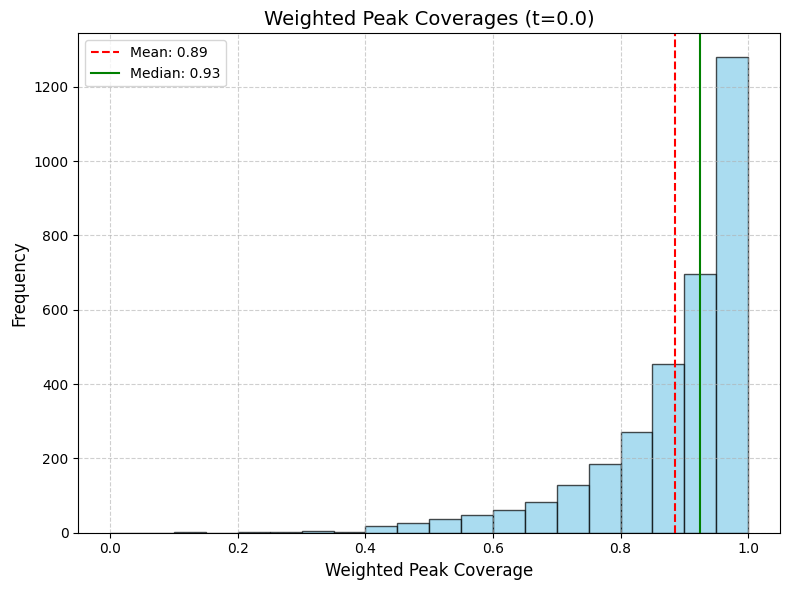

In [19]:
plot_histogram(
    w_peak_coverages[:,0], 
    bins=20, 
    x_range=(0,1),
    title=f"Weighted Peak Coverages (t={thresholds[0]})",
    x_label="Weighted Peak Coverage"
)

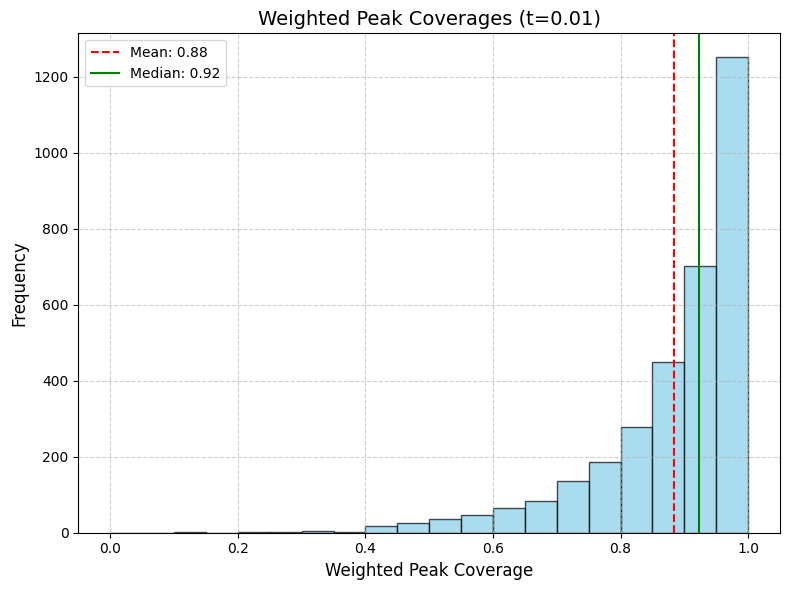

In [20]:
plot_histogram(
    w_peak_coverages[:,1], 
    bins=20, 
    x_range=(0,1),
    title=f"Weighted Peak Coverages (t={thresholds[1]})",
    x_label="Weighted Peak Coverage"
)

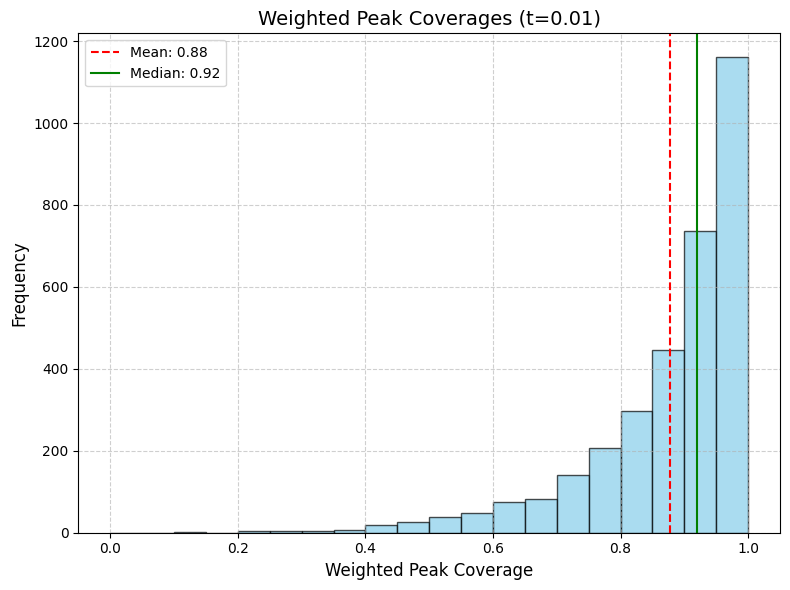

In [21]:
plot_histogram(
    w_peak_coverages[:,2], 
    bins=20, 
    x_range=(0,1),
    title=f"Weighted Peak Coverages (t={thresholds[2]})",
    x_label="Weighted Peak Coverage"
)

In [22]:
# get pred formula probabilities and strings
# get pred formula probailities
# filter formulae with prob > 0.01
# get true peak probabilities and mzs
# match true peak probabilities to ann formulae with ann mzs
# filter peaks with true intensity > 0.01
# calculate agreement between ann formulae and pred formulae, based on strings

In [23]:
# two ways of evaluating the "formula accuracy"
# first way: what % of formulae produced by NIST are in the set of formulae that can be explained by our model?
# second way: calculate a "ground-truth" formula distribution for NIST, then compare cosine similarity/JSD with ours